# 04. Baseline và so sánh thuật toán churn (Task 5)

- Train: 3 mốc 2019-01, 2019-07, 2020-01 gộp lại. **Đánh giá trên validation 2021-01.** Test 2022-01 không mở.
- Thước đo chính: **PR-AUC** (`average_precision`). Với tỷ lệ churn 67,5%, một dự đoán ngẫu nhiên cũng đạt PR-AUC ≈ 0,675, nên phải so với mốc đó chứ không so với 0.
- Thước đo kèm theo: ROC-AUC; **F1 và Recall@20% xét theo thứ hạng** (không phải theo ngưỡng 0,5): F1 khi gán nhãn churn cho 67,5% khách có điểm cao nhất (bằng tỷ lệ churn thật), Recall@20% = trong 20% khách điểm cao nhất, bắt được bao nhiêu % số khách churn. Cách này công bằng cho cả model không xuất ra xác suất. **Brier** chỉ tính cho model có xác suất (chưa hiệu chỉnh; hiệu chỉnh ở Task 6).
- Khoảng tin cậy 95% bằng bootstrap 200 lần trên validation.

In [1]:
import sys; sys.path.insert(0, "../src")
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.dummy import DummyClassifier
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score as AP, roc_auc_score as ROC, brier_score_loss, f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
import viz
from churn_data import load_churn_sets, FINAL_FEATURES
from features import FEATURES, CATEGORICAL

RNG = 0
TRAIN, va = load_churn_sets()
yt, yv = TRAIN.churn.values, va.churn.values
ALL = list(FEATURES)
print(f"Train {TRAIN.shape}, validation {va.shape}; PR-AUC ngẫu nhiên = {yv.mean():.3f}")

Train (182184, 39), validation (52771, 39); PR-AUC ngẫu nhiên = 0.675


## Cách tính các thước đo và cách đưa dữ liệu vào từng model

- **LogReg:** biến số lệch phải được `log1p` (đã kiểm ở notebook 02) rồi chuẩn hóa; thiếu giá trị điền trung vị; biến phân loại one-hot. Cần vì LogReg nhạy với thang đo.
- **Random Forest:** điền trung vị, one-hot cho biến phân loại (sklearn chưa nhận category trực tiếp). `min_samples_leaf=50` để không học thuộc.
- **LightGBM:** nhận NaN và category nguyên bản. Tham số giống notebook 03 (chưa tinh chỉnh, tinh chỉnh ở Task 6).

In [2]:
def log_pos(X):  # biến số trong bộ feature đều >= 0 trừ spend_trend (đã là log-hiệu)
    X = np.asarray(X, dtype=float)
    return np.where(X >= 0, np.log1p(np.clip(X, 0, None)), np.sign(X) * np.log1p(np.abs(X)))  # signed log

def pre(cols, scale):
    nums = [c for c in cols if c not in CATEGORICAL]; cats = [c for c in cols if c in CATEGORICAL]
    steps = [SimpleImputer(strategy="median", add_indicator=scale)]
    if scale: steps = [SimpleImputer(strategy="median", add_indicator=True), FunctionTransformer(log_pos), StandardScaler()]
    t = [("num", make_pipeline(*steps), nums)]
    if cats: t.append(("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=100), cats))
    return ColumnTransformer(t)

def make_logreg(cols):
    return make_pipeline(pre(cols, True), LogisticRegression(C=0.5, max_iter=500))
def make_rf(cols):
    return make_pipeline(pre(cols, False), RandomForestClassifier(n_estimators=300, min_samples_leaf=50, max_features="sqrt", n_jobs=-1, random_state=RNG))
PARAMS = dict(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=100, subsample=0.8, subsample_freq=1,
              colsample_bytree=0.8, reg_lambda=5, random_state=RNG, verbose=-1, n_jobs=-1)
def make_lgb(cols): return lgb.LGBMClassifier(**PARAMS)

def fit_score(make, cols):
    m = make(cols).fit(TRAIN[cols], yt)
    return m.predict_proba(va[cols])[:, 1]

def metrics(s, y=yv, proba=True):
    k = int(round(y.mean() * len(y)))
    top = np.zeros(len(y), bool); top[np.argsort(-s, kind="stable")[:k]] = True
    n20 = int(0.2 * len(y)); t20 = np.argsort(-s, kind="stable")[:n20]
    return dict(PR_AUC=AP(y, s), ROC_AUC=ROC(y, s), F1_top=f1_score(y, top), Recall_20=y[t20].sum() / y.sum(),
                Brier=brier_score_loss(y, s) if proba else np.nan)

def boot_ci(s, n=200, y=yv, fn=AP):
    r = np.random.RandomState(RNG); out = []
    for _ in range(n):
        i = r.randint(0, len(y), len(y)); out.append(fn(y[i], s[i]))
    return np.percentile(out, [2.5, 97.5])

## 1. Các model mốc (baseline)

| Model | Ý nghĩa |
| :--- | :--- |
| Dummy | Luôn đoán tỷ lệ churn của train: mốc "không biết gì" |
| Luật `recency > ngưỡng` | Cách làm thủ công phổ biến: càng lâu chưa mua càng dễ churn. Không có tham số học, điểm = `recency_days` |
| LogReg chỉ RFM | Model tuyến tính đơn giản nhất có ý nghĩa kinh doanh (`recency_days`, `frequency`, `monetary`) |

In [3]:
RFM = ["recency_days", "frequency", "monetary"]
scores = {}
scores["Dummy (tỷ lệ churn train)"] = (np.full(len(yv), yt.mean()) + np.random.RandomState(RNG).normal(0, 1e-9, len(yv)), True)
scores["Luật recency > ngưỡng"] = (va.recency_days.values.astype(float), False)
scores["LogReg chỉ RFM"] = (fit_score(make_logreg, RFM), True)
for n, (s, p) in scores.items(): print(n, {k: round(v, 4) for k, v in metrics(s, proba=p).items()})

Dummy (tỷ lệ churn train) {'PR_AUC': 0.6731, 'ROC_AUC': 0.4979, 'F1_top': 0.6724, 'Recall_20': np.float64(0.2001), 'Brier': 0.2195}
Luật recency > ngưỡng {'PR_AUC': 0.7523, 'ROC_AUC': 0.6072, 'F1_top': 0.7184, 'Recall_20': np.float64(0.2354), 'Brier': nan}
LogReg chỉ RFM {'PR_AUC': 0.8555, 'ROC_AUC': 0.7557, 'F1_top': 0.789, 'Recall_20': np.float64(0.2712), 'Brier': 0.1821}


## 2. Ba thuật toán ứng viên trên 12 biến đã lọc (Task 4)

In [4]:
cand = {}
for name, mk in [("LogReg", make_logreg), ("Random Forest", make_rf), ("LightGBM", make_lgb)]:
    cand[name] = fit_score(mk, FINAL_FEATURES); print(name, "xong")
scores.update({f"{k} (12 biến)": (v, True) for k, v in cand.items()})

rows = []
for n, (s, p) in scores.items():
    m = metrics(s, proba=p); lo, hi = boot_ci(s)
    rows.append({"model": n, **m, "PR_AUC CI95": f"[{lo:.4f}, {hi:.4f}]"})
cmp = pd.DataFrame(rows).set_index("model")
cmp.round(4)

LogReg xong


Random Forest xong


LightGBM xong


,PR_AUC,ROC_AUC,F1_top,Recall_20,Brier,PR_AUC CI95
model,,,,,,
Dummy (tỷ lệ churn train),0.6731,0.4979,0.6724,0.2001,0.2195,"[0.6686, 0.6788]"
Luật recency > ngưỡng,0.7523,0.6072,0.7184,0.2354,NaN,"[0.7476, 0.7581]"
LogReg chỉ RFM,0.8555,0.7557,0.7890,0.2712,0.1821,"[0.8520, 0.8597]"
LogReg (12 biến),0.8587,0.7587,0.7902,0.2721,0.1811,"[0.8552, 0.8624]"
Random Forest (12 biến),0.8581,0.7573,0.7894,0.2717,0.1803,"[0.8546, 0.8615]"
LightGBM (12 biến),0.8595,0.7586,0.7899,0.2715,0.1804,"[0.8562, 0.8631]"


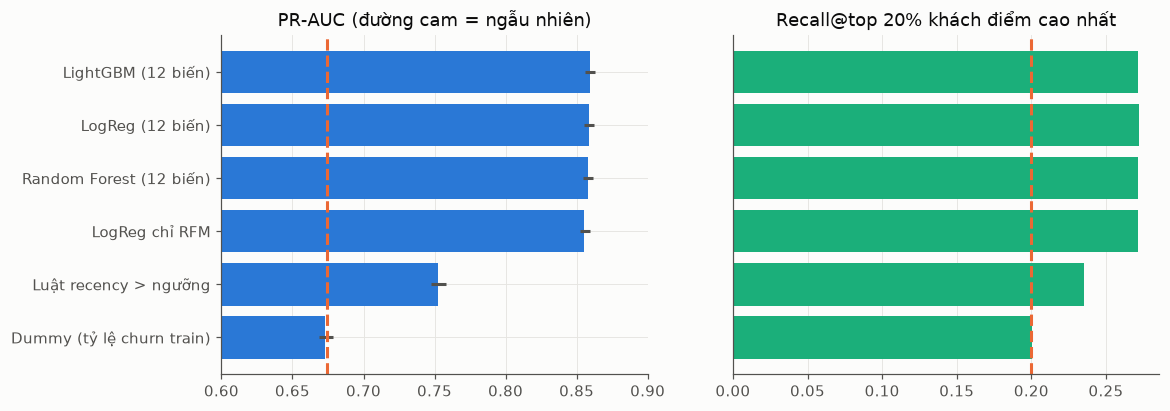

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
o = cmp.sort_values("PR_AUC")
ci = np.array([boot_ci(scores[n][0]) for n in o.index])
ax[0].barh(o.index, o.PR_AUC, xerr=[o.PR_AUC - ci[:, 0], ci[:, 1] - o.PR_AUC], color=viz.C[0], ecolor=viz.INK2)
ax[0].axvline(yv.mean(), color=viz.C[1], ls="--"); ax[0].set_xlim(0.6, 0.9)
ax[0].set_title("PR-AUC (đường cam = ngẫu nhiên)")
ax[1].barh(o.index, o.Recall_20, color=viz.C[2]); ax[1].set_yticks([]); ax[1].set_title("Recall@top 20% khách điểm cao nhất")
ax[1].axvline(0.2, color=viz.C[1], ls="--")
viz.save(fig, "04_model_comparison"); plt.show()

## 3. Ablation theo nhóm biến

Thêm từng nhóm biến theo thứ tự RFM → nhịp mua → hành vi → nhân khẩu học, dùng **LightGBM và toàn bộ 36 biến** (không dùng 12 biến đã lọc, vì lọc ở Task 4 đã loại sẵn phần lớn biến hành vi; cần xem nhóm đó có giúp gì khi chưa bị lọc). Đo phần PR-AUC tăng thêm của từng nhóm kèm khoảng tin cậy **bootstrap ghép cặp**: hai model được chấm trên cùng một mẫu bootstrap, nên khoảng tin cậy của hiệu số phản ánh đúng phần chênh lệch thật. Nếu khoảng chứa 0 thì nhóm đó **không chứng minh được** là có ích.

Thêm hai dòng đối chứng: 12 biến đã lọc, và 12 biến đó nhưng **bỏ `cancel_rate`** (nghi rò rỉ nhẹ, xem notebook 03).

In [6]:
grp = {g: [c for c in ALL if FEATURES[c][0] == g] for g in ["RFM", "Nhịp mua", "Hành vi", "Nhân khẩu học"]}
steps, acc = [], []
for g, cs in grp.items():
    acc += cs; steps.append((f"+ {g}" if steps else "RFM", list(acc)))
steps.append(("12 biến đã lọc", FINAL_FEATURES))
steps.append(("12 biến, bỏ cancel_rate", [c for c in FINAL_FEATURES if c != "cancel_rate"]))
abl = {n: fit_score(make_lgb, cols) for n, cols in steps}
r = np.random.RandomState(RNG); idx = [r.randint(0, len(yv), len(yv)) for _ in range(200)]
def bs(s): return np.array([AP(yv[i], s[i]) for i in idx])
B = {n: bs(s) for n, s in abl.items()}
rows = []; names = list(abl)
for k, n in enumerate(names):
    ref = names[k - 1] if 0 < k < 4 else None
    d = B[n] - B[ref] if ref else None
    rows.append({"cấu hình": n, "số biến": len(dict(steps)[n]), "PR_AUC": AP(yv, abl[n]), "ROC_AUC": ROC(yv, abl[n]),
                 "tăng so với dòng trên": AP(yv, abl[n]) - AP(yv, abl[ref]) if ref else np.nan,
                 "CI95 phần tăng": f"[{np.percentile(d,2.5):+.4f}, {np.percentile(d,97.5):+.4f}]" if ref else ""})
ablt = pd.DataFrame(rows).set_index("cấu hình"); ablt.round(4)

,số biến,PR_AUC,ROC_AUC,tăng so với dòng trên,CI95 phần tăng
cấu hình,,,,,
RFM,5,0.8550,0.7550,NaN,
+ Nhịp mua,13,0.8550,0.7551,-0.0000,"[-0.0004, +0.0003]"
+ Hành vi,32,0.8581,0.7579,0.0032,"[+0.0020, +0.0043]"
+ Nhân khẩu học,36,0.8587,0.7582,0.0005,"[+0.0000, +0.0010]"
12 biến đã lọc,12,0.8595,0.7586,NaN,
"12 biến, bỏ cancel_rate",11,0.8568,0.7562,NaN,


Bỏ cancel_rate: PR-AUC -0.0027, CI95 [-0.0034, -0.0018]
12 biến lọc so với đủ 36 biến: +0.0008, CI95 [+0.0002, +0.0015]


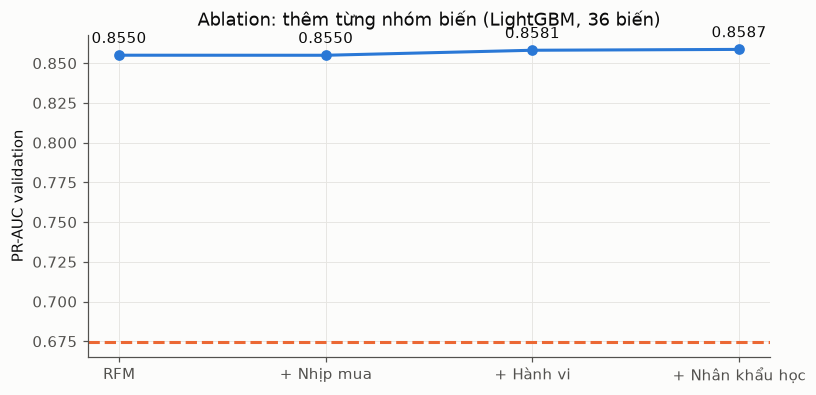

In [7]:
d = B["12 biến, bỏ cancel_rate"] - B["12 biến đã lọc"]
print(f"Bỏ cancel_rate: PR-AUC {AP(yv, abl['12 biến, bỏ cancel_rate']) - AP(yv, abl['12 biến đã lọc']):+.4f}, CI95 [{np.percentile(d,2.5):+.4f}, {np.percentile(d,97.5):+.4f}]")
d2 = B["12 biến đã lọc"] - B["+ Nhân khẩu học"]
print(f"12 biến lọc so với đủ 36 biến: {AP(yv, abl['12 biến đã lọc']) - AP(yv, abl['+ Nhân khẩu học']):+.4f}, CI95 [{np.percentile(d2,2.5):+.4f}, {np.percentile(d2,97.5):+.4f}]")
fig, ax = plt.subplots(figsize=(8, 3.8))
o = ablt.iloc[:4]; ax.plot(o.index, o.PR_AUC, "o-", color=viz.C[0]); ax.axhline(yv.mean(), color=viz.C[1], ls="--")
for i, v in enumerate(o.PR_AUC): ax.annotate(f"{v:.4f}", (i, v), textcoords="offset points", xytext=(0, 8), ha="center")
ax.set_ylabel("PR-AUC validation"); ax.set_title("Ablation: thêm từng nhóm biến (LightGBM, 36 biến)")
viz.save(fig, "04_ablation"); plt.show()

## 4. Phân tích

**Model nào tốt hơn?** Cả ba thuật toán trên 12 biến gần như bằng nhau: PR-AUC 0,8587 (LogReg), 0,8581 (RF), 0,8595 (LightGBM), khoảng tin cậy chồng lên nhau hoàn toàn (độ rộng ≈ ±0,003). Chênh lệch giữa các thuật toán không có ý nghĩa thống kê. Lý do: tín hiệu nằm chủ yếu ở một biến gần như đơn điệu (`frequency`, khách càng mua nhiều càng ít churn), nên model tuyến tính đã bắt gần hết; thêm khả năng phi tuyến của cây không có gì nhiều để khai thác. Phần còn lại là nhiễu của nhãn (39% khách bị gán churn vẫn quay lại sau đó, notebook 02).

**Cái gì tạo ra khác biệt thật:**
- Luật `recency > ngưỡng` chỉ đạt PR-AUC 0,752 và ROC-AUC 0,607, kém xa LogReg chỉ RFM (0,8555 / 0,756). Lý do: với khách đã lọc theo `L` = 3 năm, recency không phân biệt tốt bằng tần suất mua. Tức là đưa `frequency` và `monetary` vào là bước nhảy lớn nhất (+0,10 PR-AUC), vượt xa việc đổi thuật toán.
- Dummy cho PR-AUC 0,673, đúng bằng tỷ lệ churn: mốc "không biết gì".

**Ablation theo nhóm biến (LightGBM, 36 biến):**
- RFM: 0,8550.
- + Nhịp mua: **+0,0000** (CI [−0,0004, +0,0003]). Không có ích khi đã có RFM, vì `frequency` đã chứa gần hết thông tin; `mean_gap_days` chỉ giúp khi đứng một mình.
- + Hành vi: **+0,0032** (CI [+0,0020, +0,0043]). Có ích thật về mặt thống kê nhưng nhỏ (~0,4% tương đối).
- + Nhân khẩu học: +0,0005 (CI [+0,0000, +0,0010]). Gần như bằng 0.
- 12 biến đã lọc đạt 0,8595, nhỉnh hơn đủ 36 biến 0,0008 (CI [+0,0002, +0,0015]): lọc biến không làm hại, còn bớt nhiễu một chút.
- **Báo cáo trung thực:** feature hành vi và nhịp mua gần như không nâng được chất lượng dự báo so với RFM. Giá trị của chúng chủ yếu nằm ở diễn giải và phân cụm (Task 8), không phải ở độ chính xác dự báo churn.

**`cancel_rate`:** bỏ biến này làm PR-AUC giảm 0,0027 (CI [−0,0034, −0,0018]), tức đóng góp thật nhưng nhỏ. Vì nghi rò rỉ nhẹ (trạng thái đơn là trạng thái cuối), đề xuất **giữ ở model chính nhưng ghi giới hạn vào báo cáo**; bản cho web (Task 14, không có đủ thông tin trạng thái theo thời gian) nên bỏ. Cần bạn quyết định.

**Brier:** LogReg, RF, LightGBM đều ≈ 0,180–0,181, tốt hơn Dummy (0,2195) nhưng chưa hiệu chỉnh; xác suất sẽ được hiệu chỉnh ở Task 6.

**Hệ quả cho Task 6:** vì ba thuật toán ngang nhau, nên chọn theo tiêu chí phụ: LightGBM (PR-AUC cao nhất, hỗ trợ SHAP cho Task 7 và hợp với model CLV); LogReg là phương án dự phòng dễ giải thích. Nên tinh chỉnh LightGBM và so với LogReg đã hiệu chỉnh.